In [1]:

# Step 1: Install the UCI dataset library
!pip -q install ucimlrepo

# Step 2: Import the required library
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Step 3: Fetch the official UCI dataset (ID 891)
cdc = fetch_ucirepo(id=891)

# Step 4: Combine the features and target
X = cdc.data.features
y = cdc.data.targets

df = pd.concat([X, y], axis=1)

# Step 5: Check the dataset
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Step 6: Preview the first five rows
df.head()

Dataset downloaded successfully!
Dataset shape: (253680, 22)

Column names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [2]:

# Count records in each target class
print("Target counts:")
print(df["Diabetes_binary"].value_counts().sort_index())

# Calculate class percentages
print("\nTarget percentages:")
print(
    (df["Diabetes_binary"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Target counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


In [3]:

# 1. Check missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# 2. Calculate the total number of missing cells
print("\nTotal missing cells:", df.isnull().sum().sum())

# 3. Check column data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check dataset dimensions
print("\nDataset dimensions:", df.shape)

Missing values per column:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64

Total missing cells: 0

Column data types:
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare 

In [4]:

# Statistical summary of all 22 columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [5]:

# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print(
    "Percentage of duplicate rows:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

Number of duplicate rows: 24206
Percentage of duplicate rows: 9.54 %


In [6]:

# Count exact duplicates separately by target class
duplicate_mask = df.duplicated()

print("Duplicate rows by target class:")
print(df.loc[duplicate_mask, "Diabetes_binary"].value_counts().sort_index())

print("\nTarget distribution in the complete dataset:")
print(df["Diabetes_binary"].value_counts().sort_index())

Duplicate rows by target class:
Diabetes_binary
0    23957
1      249
Name: count, dtype: int64

Target distribution in the complete dataset:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64


In [7]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/"
    "ML Coursework Project/01 CDC Diabetes/Dataset"
)

folder.mkdir(parents=True, exist_ok=True)

file_path = folder / "CDC_Diabetes_Health_Indicators.csv"

df.to_csv(file_path, index=False)

print("Saved:", file_path)
print("Dataset shape:", df.shape)

Saved: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset shape: (253680, 22)


In [8]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [9]:

import os

print("Drive folder exists:", os.path.exists("/content/drive"))
print("MyDrive exists:", os.path.exists("/content/drive/MyDrive"))

if os.path.exists("/content/drive"):
    print("Contents:", os.listdir("/content/drive")[:10])

Drive folder exists: True
MyDrive exists: True
Contents: ['MyDrive']


In [10]:

import os

path = "/content/drive/MyDrive"

print("MyDrive accessible:", os.path.isdir(path))
print("Number of items:", len(os.listdir(path)))
print("First few items:", os.listdir(path)[:10])

MyDrive accessible: True
Number of items: 1
First few items: ['PhD']


In [11]:

from pathlib import Path

# Locate your PhD project folder
folder = Path(
    "/content/drive/MyDrive/PhD/"
    "ML Coursework Project/01 CDC Diabetes/Dataset"
)

# Create any missing folders
folder.mkdir(parents=True, exist_ok=True)

# Save the original dataset
file_path = folder / "CDC_Diabetes_Health_Indicators.csv"
df.to_csv(file_path, index=False)

# Confirm the save
print("Dataset saved successfully!")
print("File location:", file_path)
print("Dataset shape:", df.shape)
print("File size (MB):", round(file_path.stat().st_size / (1024**2), 2))

Dataset saved successfully!
File location: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset shape: (253680, 22)
File size (MB): 11.04


In [12]:

import pandas as pd

saved_df = pd.read_csv(file_path)

print("Saved file verified:", file_path.exists())
print("Saved dataset shape:", saved_df.shape)
print("Missing cells:", saved_df.isnull().sum().sum())

Saved file verified: True
Saved dataset shape: (253680, 22)
Missing cells: 0


Target class counts:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Target class percentages:
Diabetes_binary
0    86.07
1    13.93
Name: proportion, dtype: float64


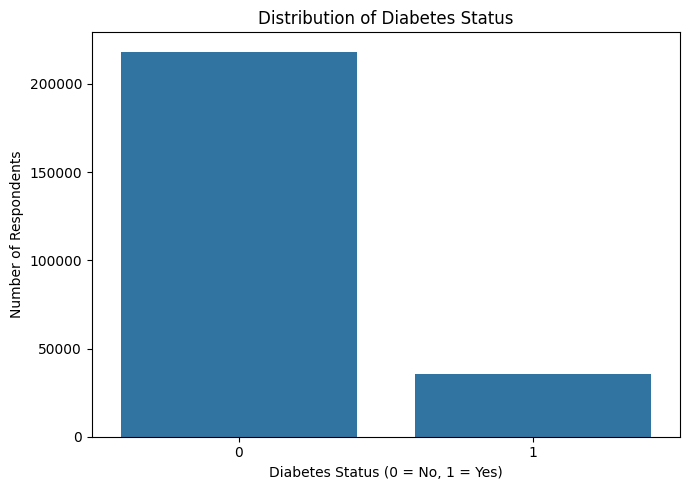

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count the two target classes
target_counts = df["Diabetes_binary"].value_counts().sort_index()

print("Target class counts:")
print(target_counts)

print("\nTarget class percentages:")
print((df["Diabetes_binary"].value_counts(normalize=True).sort_index() * 100).round(2))

# Plot the target distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Diabetes_binary")
plt.title("Distribution of Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

Diabetes status by high blood pressure (%):
                No Diabetes (0)  Diabetes (1)
No High BP (0)            93.96          6.04
High BP (1)               75.55         24.45


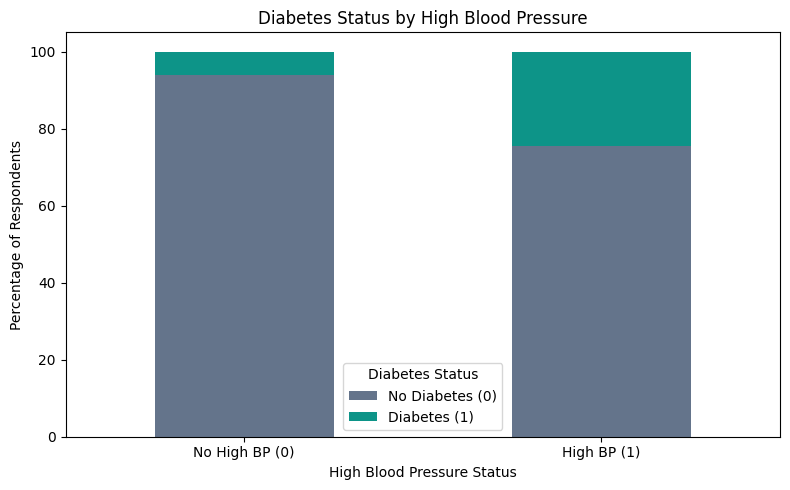

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes percentages by high blood pressure status
bp_table = pd.crosstab(
    df["HighBP"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

bp_table.index = ["No High BP (0)", "High BP (1)"]
bp_table.columns = ["No Diabetes (0)", "Diabetes (1)"]

print("Diabetes status by high blood pressure (%):")
print(bp_table.round(2))

# Plot the percentages
bp_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#64748b", "#0d9488"]
)

plt.title("Diabetes Status by High Blood Pressure")
plt.xlabel("High Blood Pressure Status")
plt.ylabel("Percentage of Respondents")
plt.xticks(rotation=0)
plt.legend(title="Diabetes Status")
plt.tight_layout()
plt.show()

In [15]:

from pathlib import Path

file_path = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
)

print("File exists:", file_path.exists())
print("Full path:", file_path)
print("Dataset folder contents:")

if file_path.parent.exists():
    for item in file_path.parent.iterdir():
        print(item.name)
else:
    print("Dataset folder does not exist at this path.")

File exists: True
Full path: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Dataset folder contents:
CDC_Diabetes_Health_Indicators.csv


In [16]:

from google.colab import drive
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset"
)

print("Files saved in Dataset folder:")
for file in folder.iterdir():
    print("📄", file.name)

print("\nOpen Google Drive in your browser:")
print("https://drive.google.com/drive/my-drive")

Files saved in Dataset folder:
📄 CDC_Diabetes_Health_Indicators.csv

Open Google Drive in your browser:
https://drive.google.com/drive/my-drive


In [17]:

from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Folders inside My Drive:")
for item in base.iterdir():
    print("📁" if item.is_dir() else "📄", repr(item.name))

print("\nFolders inside PhD:")
phd = base / "PhD"
if phd.exists():
    for item in phd.iterdir():
        print("📁" if item.is_dir() else "📄", repr(item.name))
else:
    print("PhD folder not found")

Folders inside My Drive:
📁 'PhD'

Folders inside PhD:
📁 'ML Coursework Project'


In [18]:

from pathlib import Path

project = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project"
)

print("Folders and files inside ML Coursework Project:\n")

for item in project.iterdir():
    print("📁" if item.is_dir() else "📄", item.name)

cdc = project / "01 CDC Diabetes"

print("\nDoes 01 CDC Diabetes exist?", cdc.exists())

if cdc.exists():
    print("\nContents of 01 CDC Diabetes:")
    for item in cdc.iterdir():
        print("📁" if item.is_dir() else "📄", item.name)

Folders and files inside ML Coursework Project:

📁 01 CDC Diabetes

Does 01 CDC Diabetes exist? True

Contents of 01 CDC Diabetes:
📁 Dataset


In [19]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset"
)

file_path = folder / "CDC_Diabetes_Health_Indicators.csv"

print("Dataset folder exists:", folder.exists())
print("CSV exists:", file_path.exists())

if file_path.exists():
    print("File size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")
    print("Last modified:", file_path.stat().st_mtime)

print("\nFull folder path:")
print(folder)

Dataset folder exists: True
CSV exists: True
File size: 11.04 MB
Last modified: 1790684567.1182966

Full folder path:
/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset


In [20]:

from pathlib import Path
import shutil

source = Path(
    "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
)

backup = Path(
    "/content/drive/MyDrive/CDC_Diabetes_Backup.csv"
)

shutil.copy2(source, backup)

print("Backup exists:", backup.exists())
print("Backup size (MB):", round(backup.stat().st_size / (1024 * 1024), 2))
print("Backup location:", backup)

Backup exists: True
Backup size (MB): 11.04
Backup location: /content/drive/MyDrive/CDC_Diabetes_Backup.csv


In [21]:

from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Top-level files and folders:")
for item in base.iterdir():
    print(item.name)

backup = base / "CDC_Diabetes_Backup.csv"
original = base / "PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"

print("\nBackup exists:", backup.exists())
print("Original exists:", original.exists())

Top-level files and folders:
PhD
CDC_Diabetes_Backup.csv

Backup exists: True
Original exists: True


In [22]:

from google.colab import drive

drive.flush_and_unmount()
print("Google Drive disconnected safely.")

Drive not mounted, so nothing to flush and unmount.
Google Drive disconnected safely.


In [23]:

from google.colab import drive

drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [24]:

import os

mount_path = "/content/drive"

print("Drive path exists:", os.path.exists(mount_path))
print("Is a directory:", os.path.isdir(mount_path))

if os.path.isdir(mount_path):
    print("Contents:", os.listdir(mount_path))

Drive path exists: True
Is a directory: True
Contents: ['MyDrive']


In [25]:

from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive")

original = base / "PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"
backup = base / "CDC_Diabetes_Backup.csv"

for path in [original, backup]:
    print("\nFile:", path)
    print("Exists:", path.exists())

    if path.exists():
        try:
            test_df = pd.read_csv(path, nrows=5)
            print("Readable: Yes")
            print("Columns:", len(test_df.columns))
            print("File size (MB):", round(path.stat().st_size / (1024 * 1024), 2))
        except Exception as e:
            print("Read error:", repr(e))


File: /content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv
Exists: True
Readable: Yes
Columns: 22
File size (MB): 11.04

File: /content/drive/MyDrive/CDC_Diabetes_Backup.csv
Exists: True
Readable: Yes
Columns: 22
File size (MB): 11.04


In [26]:

from google.colab import files

file_path = "/content/drive/MyDrive/PhD/ML Coursework Project/01 CDC Diabetes/Dataset/CDC_Diabetes_Health_Indicators.csv"

files.download(file_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

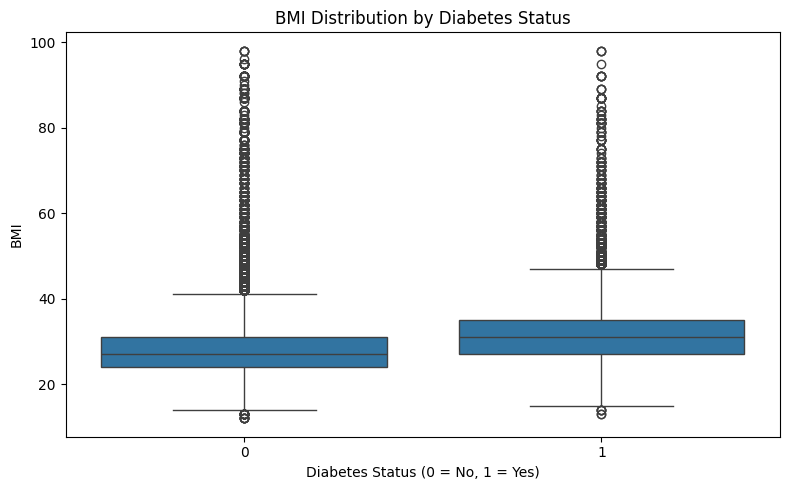

BMI summary by diabetes status:
                    count   mean   std   min   25%   50%   75%   max
Diabetes_binary                                                     
0                218334.0  27.81  6.29  12.0  24.0  27.0  31.0  98.0
1                 35346.0  31.94  7.36  13.0  27.0  31.0  35.0  98.0


In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

# Compare BMI across diabetes-status groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diabetes_binary",
    y="BMI"
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# Summarise BMI in each group
print("BMI summary by diabetes status:")
print(
    df.groupby("Diabetes_binary")["BMI"]
      .describe()
      .round(2)
)

Diabetes status by age category (%):
     No Diabetes (%)  Diabetes (%)
Age                               
1              98.63          1.37
2              98.16          1.84
3              97.18          2.82
4              95.47          4.53
5              93.50          6.50
6              91.21          8.79
7              88.26         11.74
8              86.17         13.83
9              82.75         17.25
10             79.63         20.37
11             78.15         21.85
12             78.70         21.30
13             81.52         18.48


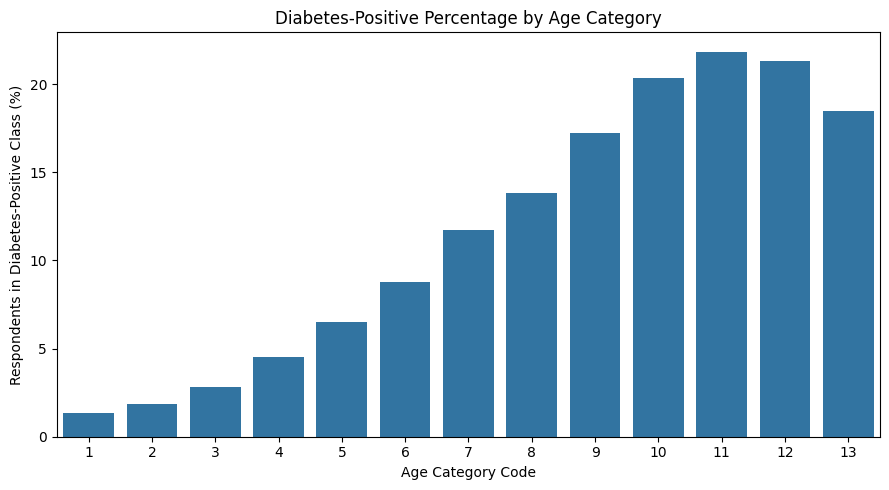

In [28]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes percentages within each age category
age_table = pd.crosstab(
    df["Age"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

age_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by age category (%):")
print(age_table.round(2))

# Plot diabetes-positive percentage by age category
plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_table.index,
    y=age_table["Diabetes (%)"]
)

plt.title("Diabetes-Positive Percentage by Age Category")
plt.xlabel("Age Category Code")
plt.ylabel("Respondents in Diabetes-Positive Class (%)")
plt.tight_layout()
plt.show()

Diabetes status by general health category (%):
         No Diabetes (%)  Diabetes (%)
GenHlth                               
1                  97.48          2.52
2                  92.84          7.16
3                  82.21         17.79
4                  68.99         31.01
5                  62.11         37.89


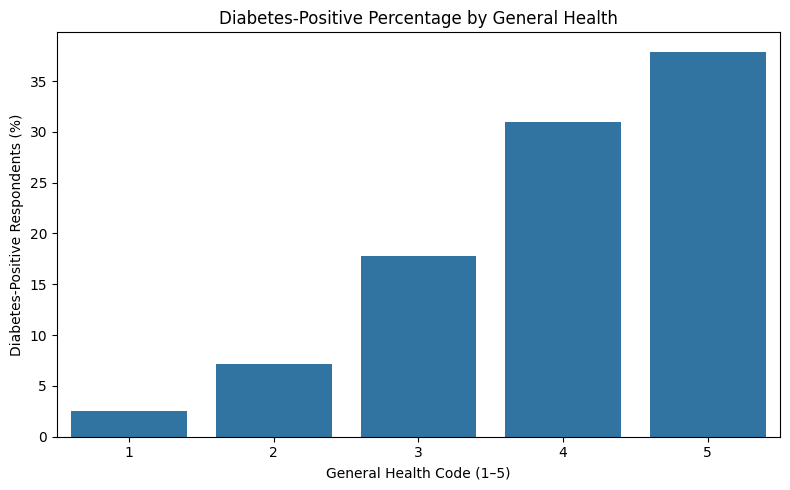

In [29]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate diabetes-positive percentages within each health category
health_table = pd.crosstab(
    df["GenHlth"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

health_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by general health category (%):")
print(health_table.round(2))

# Plot the results
plt.figure(figsize=(8, 5))

sns.barplot(
    x=health_table.index,
    y=health_table["Diabetes (%)"]
)

plt.title("Diabetes-Positive Percentage by General Health")
plt.xlabel("General Health Code (1–5)")
plt.ylabel("Diabetes-Positive Respondents (%)")
plt.tight_layout()
plt.show()

In [30]:

chol_table = pd.crosstab(
    df["HighChol"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

chol_table.index = ["No High Cholesterol (0)", "High Cholesterol (1)"]
chol_table.columns = ["No Diabetes (%)", "Diabetes (%)"]

print("Diabetes status by high cholesterol (%):")
print(chol_table.round(2))

Diabetes status by high cholesterol (%):
                         No Diabetes (%)  Diabetes (%)
No High Cholesterol (0)            92.02          7.98
High Cholesterol (1)               77.99         22.01


In [31]:

activity_table = pd.crosstab(
    df["PhysActivity"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

activity_table.index = [
    "No physical activity (0)",
    "Physical activity (1)"
]
activity_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by physical activity (%):")
print(activity_table.round(2))

Diabetes status by physical activity (%):
                          No Diabetes (%)  Diabetes (%)
No physical activity (0)            78.86         21.14
Physical activity (1)               88.39         11.61


In [32]:
combined_table = pd.crosstab(
    [df["HighBP"], df["HighChol"]],
    df["Diabetes_binary"],
    normalize="index"
) * 100

combined_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by blood pressure and cholesterol (%):")
print(combined_table.round(2))

Diabetes status by blood pressure and cholesterol (%):
                 No Diabetes (%)  Diabetes (%)
HighBP HighChol                               
0      0                   95.81          4.19
       1                   89.58         10.42
1      0                   83.27         16.73
       1                   70.29         29.71


In [33]:
age_table = pd.crosstab(
    df["Age"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

age_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by age category (%):")
print(age_table.round(2))

Diabetes status by age category (%):
     No Diabetes (%)  Diabetes (%)
Age                               
1              98.63          1.37
2              98.16          1.84
3              97.18          2.82
4              95.47          4.53
5              93.50          6.50
6              91.21          8.79
7              88.26         11.74
8              86.17         13.83
9              82.75         17.25
10             79.63         20.37
11             78.15         21.85
12             78.70         21.30
13             81.52         18.48


In [34]:
income_table = pd.crosstab(
    df["Income"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

income_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by income category (%):")
print(income_table.round(2))

Diabetes status by income category (%):
        No Diabetes (%)  Diabetes (%)
Income                               
1                 75.71         24.29
2                 73.81         26.19
3                 77.69         22.31
4                 79.87         20.13
5                 82.60         17.40
6                 85.49         14.51
7                 87.82         12.18
8                 92.04          7.96


In [35]:
education_table = pd.crosstab(
    df["Education"],
    df["Diabetes_binary"],
    normalize="index"
) * 100

education_table.columns = [
    "No Diabetes (%)",
    "Diabetes (%)"
]

print("Diabetes status by education category (%):")
print(education_table.round(2))

Diabetes status by education category (%):
           No Diabetes (%)  Diabetes (%)
Education                               
1                    72.99         27.01
2                    70.74         29.26
3                    75.78         24.22
4                    82.36         17.64
5                    85.19         14.81
6                    90.31          9.69


In [36]:
print("Dataset shape:", df.shape)

print("\nTarget values:")
print(df["Diabetes_binary"].value_counts().sort_index())

print("\nAge categories:")
print(sorted(df["Age"].unique()))

print("\nEducation categories:")
print(sorted(df["Education"].unique()))

print("\nIncome categories:")
print(sorted(df["Income"].unique()))

Dataset shape: (253680, 22)

Target values:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

Age categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

Education categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Income categories:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
